<a href="https://colab.research.google.com/github/bcarmoai/ML-and-AI/blob/main/PyTorch_image_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Imports, Setup, and Data Loading
First, we'll import the necessary libraries, configure the computing device (GPU if available, else CPU), and load the CIFAR-10 dataset using `torchvision`.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Setup device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# 1. Load and preprocess the CIFAR-10 dataset
# ToTensor() automatically converts images to [0, 1] range, equivalent to dividing by 255.0
transform = transforms.Compose([transforms.ToTensor()])

batch_size = 64

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

Using device: cpu


100%|██████████| 170M/170M [13:03<00:00, 218kB/s]


### 2. Define the CNN Model
In PyTorch, we define a model by subclassing `nn.Module`. We'll recreate the exact architecture used in the TensorFlow demo.

In [6]:
# 2. Build the Convolutional Neural Network (CNN)
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # PyTorch expects channels first: (batch, channels, height, width)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=0)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=0)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv3 = nn.Conv2d(64, 64, kernel_size=3, padding=0)
        self.relu3 = nn.ReLU()

        self.flatten = nn.Flatten()
        # After 3 convs (without padding) and 2 pools, the 32x32 image becomes 4x4
        self.fc1 = nn.Linear(64 * 4 * 4, 64)
        self.relu4 = nn.ReLU()
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.relu3(self.conv3(x))
        x = self.flatten(x)
        x = self.relu4(self.fc1(x))
        x = self.fc2(x)
        return x

model = SimpleCNN().to(device)

# 3. Compile the model equivalent (Loss and Optimizer)
criterion = nn.CrossEntropyLoss() # Includes softmax implicitly like from_logits=True
optimizer = optim.Adam(model.parameters(), lr=0.001)

### 3. Training Loop
Unlike Keras's `model.fit()`, PyTorch requires a manual training loop. We will also track training and validation accuracy to recreate the history plot later.

In [7]:
# 4. Train the model
epochs = 5
history = {'accuracy': [], 'val_accuracy': []}

for epoch in range(epochs):
    # Training Phase
    model.train()
    running_corrects = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    train_acc = running_corrects.double() / total_train
    history['accuracy'].append(train_acc.item())

    # Validation Phase
    model.eval()
    val_corrects = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            val_corrects += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    val_acc = val_corrects.double() / total_val
    history['val_accuracy'].append(val_acc.item())

    print(f'Epoch {epoch+1}/{epochs} - Train Acc: {train_acc:.4f} - Val Acc: {val_acc:.4f}')

Epoch 1/5 - Train Acc: 0.3962 - Val Acc: 0.4804
Epoch 2/5 - Train Acc: 0.5244 - Val Acc: 0.5492
Epoch 3/5 - Train Acc: 0.5797 - Val Acc: 0.5911
Epoch 4/5 - Train Acc: 0.6185 - Val Acc: 0.6198
Epoch 5/5 - Train Acc: 0.6461 - Val Acc: 0.6239


### 4. Evaluate and Make a Prediction
We'll pick a single image from the test set, evaluate the prediction, and plot it.


Final Test Accuracy: 0.6239


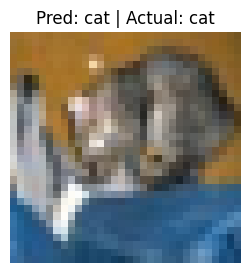

In [8]:
# 5. Evaluate the model
print(f'\nFinal Test Accuracy: {history["val_accuracy"][-1]:.4f}')

# 6. Make a prediction on a sample image
model.eval()
sample_index = 0
sample_image_tensor, sample_label_idx = test_dataset[sample_index]
actual_label = class_names[sample_label_idx]

# Add batch dimension and move to device
input_tensor = sample_image_tensor.unsqueeze(0).to(device)

with torch.no_grad():
    outputs = model(input_tensor)
    _, predicted = torch.max(outputs, 1)
    predicted_label = class_names[predicted[0].item()]

# Plot the result (Convert PyTorch tensor [C, H, W] to numpy [H, W, C] for Matplotlib)
sample_image_np = sample_image_tensor.permute(1, 2, 0).numpy()

plt.figure(figsize=(3,3))
plt.imshow(sample_image_np)
plt.title(f"Pred: {predicted_label} | Actual: {actual_label}")
plt.axis('off')
plt.show()

### 5. Plot Accuracy History
Plotting the training and validation accuracy that we tracked during our custom training loop.

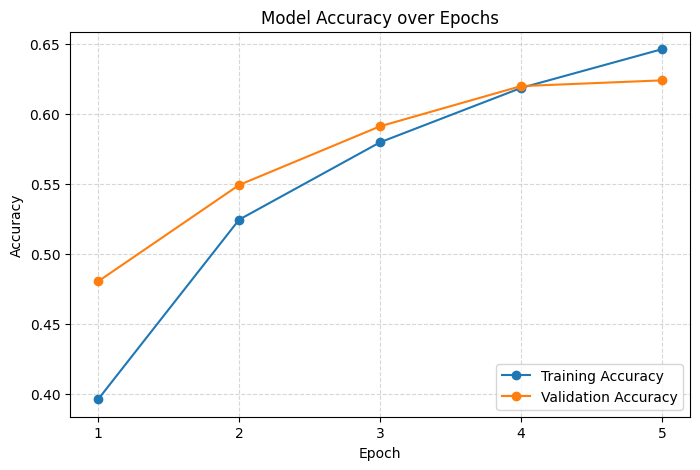

In [9]:
# Plot training & validation accuracy values
plt.figure(figsize=(8, 5))
plt.plot(history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Model Accuracy over Epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
# Adjust epoch ticks to 1-based indexing for better readability
plt.xticks(range(len(history['accuracy'])), range(1, len(history['accuracy'])+1))
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 6. Confusion Matrix
Let's get the predictions for the entire test set and visualize the confusion matrix.

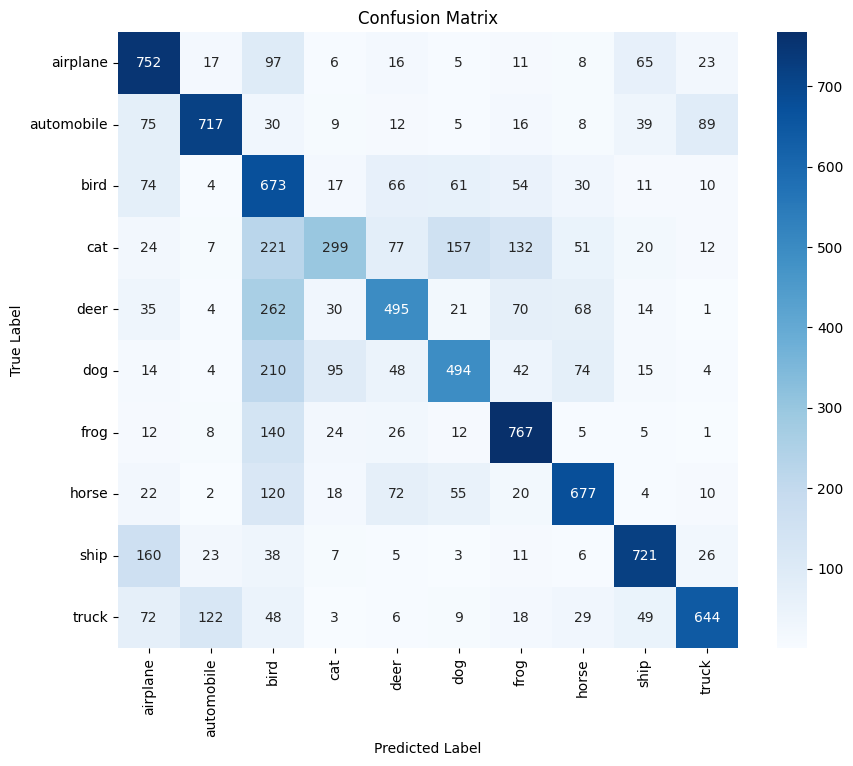

In [10]:
# 1. Get predictions for the entire test dataset
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 2. Compute the confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# 3. Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()